In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

t = pd.read_csv("../data/processed/training_table.csv.gz", parse_dates=["date"])
print(t.shape)
print("Dates:", t["date"].min().date(), "to", t["date"].max().date(), "| Sites:", t["site_id"].nunique())
print("Missing values per column:\n", t.isna().sum()[t.isna().sum() > 0])
print(f"\nLabel = 1 on {t['label'].mean():.1%} of site-days")
t.describe().T.round(2)

(188448, 23)
Dates: 2015-01-30 to 2024-12-31 | Sites: 52
Missing values per column:
 Series([], dtype: int64)

Label = 1 on 4.2% of site-days


,count,mean,min,25%,50%,75%,max,std
date,188448,2020-01-15 12:00:00,2015-01-30 00:00:00,2017-07-23 18:00:00,2020-01-15 12:00:00,2022-07-09 06:00:00,2024-12-31 00:00:00,NaN
temperature_2m_max,188448.0,80.880136,31.0,76.1,82.7,87.3,104.3,8.970554
apparent_temperature_max,188448.0,84.9959,21.6,77.0,86.9,95.6,112.9,13.242673
precipitation_sum,188448.0,0.151445,0.0,0.0,0.02,0.165,9.504,0.330759
precipitation_hours,188448.0,4.307942,0.0,0.0,3.0,7.0,24.0,5.024999
wind_gusts_10m_max,188448.0,22.447669,6.3,17.9,21.5,25.7,142.3,6.873699
rain_3d_in,188448.0,0.454309,0.0,0.02,0.185,0.641,14.173,0.690355
rain_7d_in,188448.0,1.059475,0.0,0.188,0.693,1.547,15.516,1.187994
rain_30d_in,188448.0,4.545942,0.008,1.98,3.75,6.499,23.864,3.249908
days_since_rain,188448.0,1.526511,0.0,0.0,0.0,2.0,42.0,2.778919


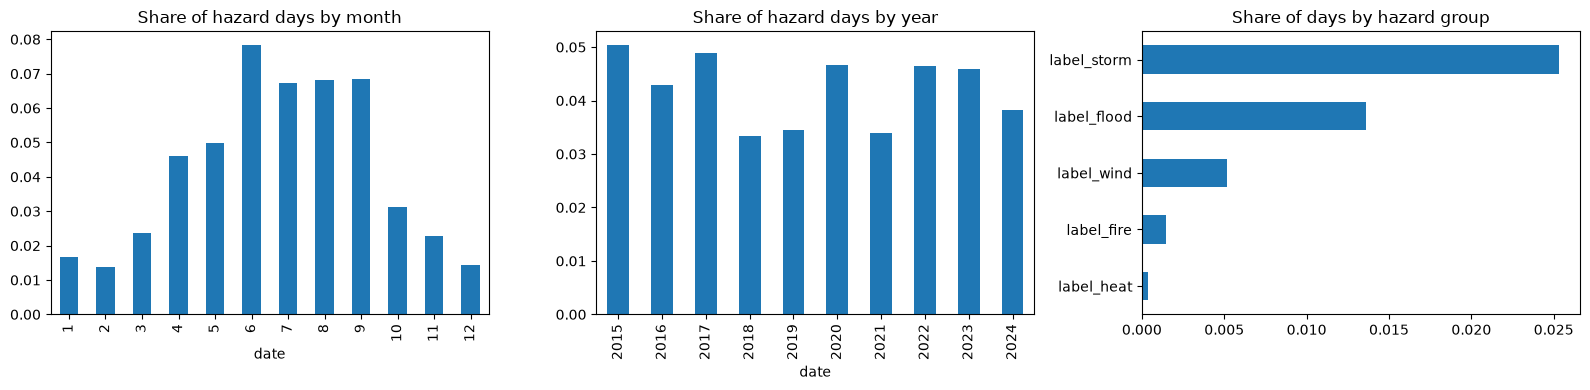

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
t.groupby(t["date"].dt.month)["label"].mean().plot(kind="bar", ax=axes[0], title="Share of hazard days by month")
t.groupby(t["date"].dt.year)["label"].mean().plot(kind="bar", ax=axes[1], title="Share of hazard days by year")
groups = [c for c in t.columns if c.startswith("label_")]
t[groups].mean().sort_values().plot(kind="barh", ax=axes[2], title="Share of days by hazard group")
plt.tight_layout(); plt.show()

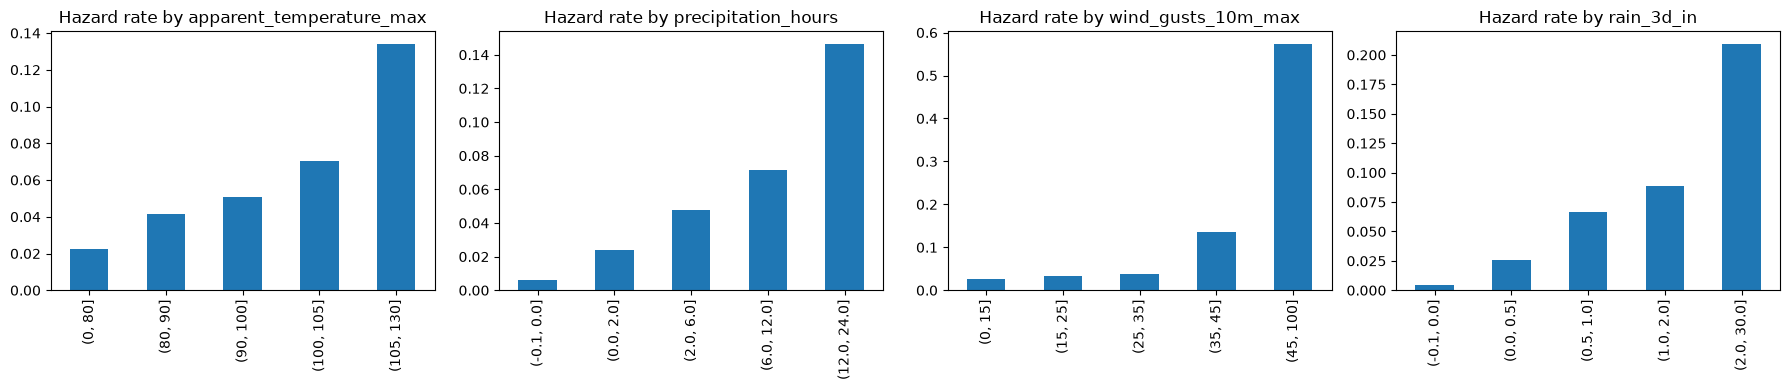

In [23]:
checks = {
    "apparent_temperature_max": [0, 80, 90, 100, 105, 130],
    "precipitation_hours": [-0.1, 0, 2, 6, 12, 24],
    "wind_gusts_10m_max": [0, 15, 25, 35, 45, 100],
    "rain_3d_in": [-0.1, 0, 0.5, 1, 2, 30],
}
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (col, bins) in zip(axes, checks.items()):
    t.groupby(pd.cut(t[col], bins), observed=True)["label"].mean().plot(kind="bar", ax=ax, title=f"Hazard rate by {col}")
    ax.set_xlabel("")
plt.tight_layout(); plt.show()

In [24]:
FEATURES = ["temperature_2m_max", "apparent_temperature_max", "precipitation_sum", "precipitation_hours",
            "wind_gusts_10m_max", "rain_3d_in", "rain_7d_in", "rain_30d_in", "days_since_rain",
            "heavy_rain_day", "season_sin", "season_cos", "lat", "lon"]
year = t["date"].dt.year
train, val, test = t[year <= 2021], t[year == 2022], t[year >= 2023]
X_tr, y_tr = train[FEATURES], train["label"]
X_va, y_va = val[FEATURES], val["label"]
X_te, y_te = test[FEATURES], test["label"]
print(f"Train {len(train):,} rows (2015–2021, {y_tr.mean():.1%} positive)")
print(f"Val   {len(val):,} rows (2022, {y_va.mean():.1%} positive)")
print(f"Test  {len(test):,} rows (2023–2024, {y_te.mean():.1%} positive) — only touched once, at the end")

Train 131,456 rows (2015–2021, 4.1% positive)
Val   18,980 rows (2022, 4.6% positive)
Test  38,012 rows (2023–2024, 4.2% positive) — only touched once, at the end


In [25]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import lightgbm as lgb

def scores(y, p):
    return {"ROC AUC": roc_auc_score(y, p), "PR AUC": average_precision_score(y, p), "Brier": brier_score_loss(y, p)}

results, preds = {}, {}

# Baseline 1: seasonal climatology — the historical hazard rate for that month.
month_rate = train.groupby(train["date"].dt.month)["label"].mean()
preds["Baseline: month only"] = val["date"].dt.month.map(month_rate).to_numpy()

# Baseline 2: heat only — what a simple heat-index rule would give.
heat = LogisticRegression(max_iter=1000).fit(X_tr[["apparent_temperature_max"]], y_tr)
preds["Baseline: heat only"] = heat.predict_proba(X_va[["apparent_temperature_max"]])[:, 1]

logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(X_tr, y_tr)
preds["Logistic regression"] = logreg.predict_proba(X_va)[:, 1]

forest = RandomForestClassifier(n_estimators=300, min_samples_leaf=50, n_jobs=-1, random_state=42).fit(X_tr, y_tr)
preds["Random forest"] = forest.predict_proba(X_va)[:, 1]

gbm = lgb.LGBMClassifier(n_estimators=2000, learning_rate=0.03, num_leaves=31, min_child_samples=100,
                         subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=42, verbose=-1)
gbm.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], eval_metric="average_precision",
        callbacks=[lgb.early_stopping(100, verbose=False)])
preds["LightGBM"] = gbm.predict_proba(X_va)[:, 1]
print("LightGBM stopped at", gbm.best_iteration_, "trees")

for name, p in preds.items():
    results[name] = scores(y_va, p)
comparison = pd.DataFrame(results).T.sort_values("PR AUC", ascending=False).round(4)
comparison

LightGBM stopped at 90 trees


,ROC AUC,PR AUC,Brier
Random forest,0.8740,0.3653,0.0362
LightGBM,0.8784,0.3646,0.0360
Logistic regression,0.8544,0.3168,0.0372
Baseline: heat only,0.6076,0.0816,0.0440
Baseline: month only,0.6563,0.0728,0.0438


In [26]:
models = {"Logistic regression": logreg, "Random forest": forest, "LightGBM": gbm}
best_name = comparison.drop(index=[i for i in comparison.index if i.startswith("Baseline")]).index[0]
best = models[best_name]
p_test = best.predict_proba(X_te)[:, 1]
base_test = test["date"].dt.month.map(month_rate).to_numpy()
print("Best on validation:", best_name)
pd.DataFrame({best_name: scores(y_te, p_test), "Baseline: month only": scores(y_te, base_test)}).T.round(4)

Best on validation: Random forest


,ROC AUC,PR AUC,Brier
Random forest,0.8876,0.3501,0.0330
Baseline: month only,0.6645,0.0650,0.0397


In [27]:
import os
REPORTS = "../reports"
os.makedirs(REPORTS, exist_ok=True)

compare = {"Random forest": forest, "LightGBM": gbm}
p_test_all = {name: m.predict_proba(X_te)[:, 1] for name, m in compare.items()}
base_test = test["date"].dt.month.map(month_rate).to_numpy()
rows = {name: scores(y_te, p) for name, p in p_test_all.items()}
rows["Baseline: month only"] = scores(y_te, base_test)
test_table = pd.DataFrame(rows).T.round(4)
test_table.to_csv(f"{REPORTS}/test_scores_2023_2024.csv")
test_table

,ROC AUC,PR AUC,Brier
Random forest,0.8876,0.3501,0.0330
LightGBM,0.8894,0.3580,0.0326
Baseline: month only,0.6645,0.0650,0.0397


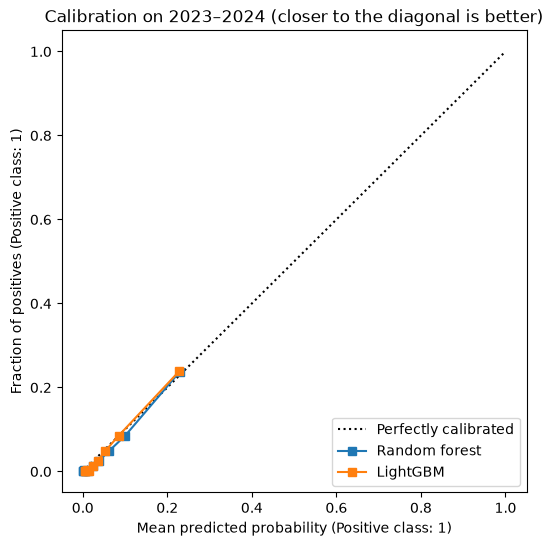

In [28]:
from sklearn.calibration import CalibrationDisplay
fig, ax = plt.subplots(figsize=(6, 6))
for name, p in p_test_all.items():
    CalibrationDisplay.from_predictions(y_te, p, n_bins=10, strategy="quantile", name=name, ax=ax)
ax.set_title("Calibration on 2023–2024 (closer to the diagonal is better)")
plt.savefig(f"{REPORTS}/calibration_both.png", dpi=150, bbox_inches="tight")
plt.show()

/opt/anaconda3/envs/cypressWatch/lib/python3.11/site-packages/shap/explainers/_tree.py:620: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


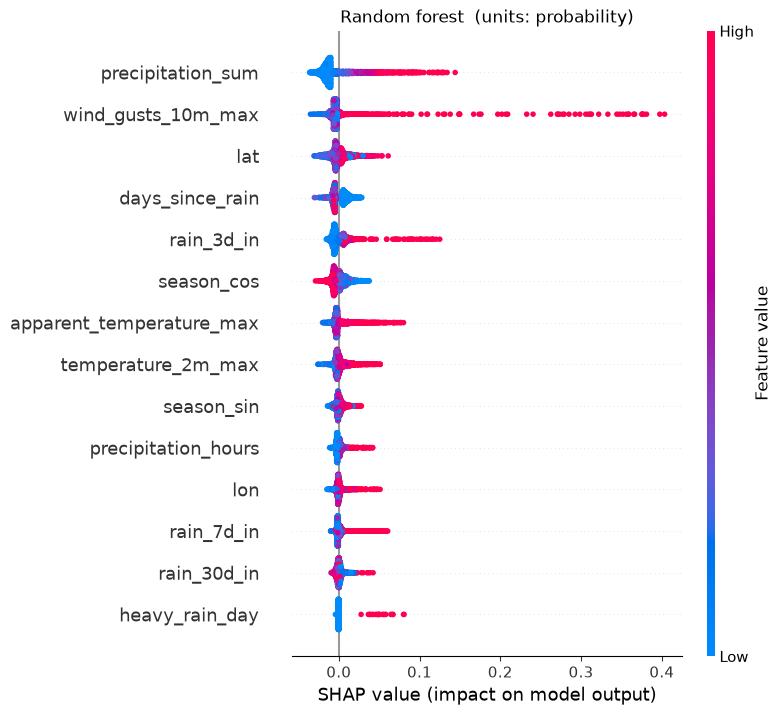

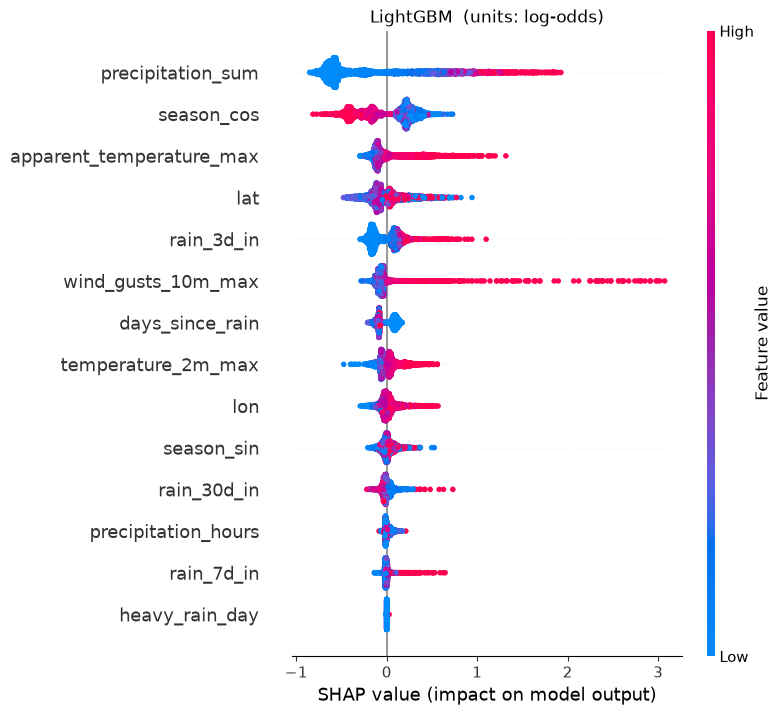

In [29]:
import shap
sample = X_te.sample(min(3000, len(X_te)), random_state=0)

def tree_shap(model, data):
    sv = shap.TreeExplainer(model).shap_values(data)
    if isinstance(sv, list):        # older shap: one array per class
        sv = sv[1]
    elif np.ndim(sv) == 3:          # newer shap: (rows, features, classes)
        sv = sv[..., 1]
    return sv

shap_all = {name: tree_shap(m, sample) for name, m in compare.items()}
for name, sv in shap_all.items():
    plt.figure()
    shap.summary_plot(sv, sample, show=False)
    plt.title(name + ("  (units: probability)" if name == "Random forest" else "  (units: log-odds)"))
    plt.savefig(f"{REPORTS}/shap_{name.replace(' ', '_').lower()}.png", dpi=150, bbox_inches="tight")
    plt.show()

In [30]:
importance = pd.DataFrame({name: np.abs(sv).mean(axis=0) for name, sv in shap_all.items()}, index=FEATURES)
agreement = round(importance.corr(method="spearman").iloc[0, 1], 2)
ranks = importance.rank(ascending=False).astype(int).sort_values("LightGBM")
ranks.columns = [f"{c} rank" for c in ranks.columns]
ranks.to_csv(f"{REPORTS}/feature_rank_agreement.csv")
print("Rank agreement (Spearman):", agreement)
ranks

Rank agreement (Spearman): 0.84


,Random forest rank,LightGBM rank
precipitation_sum,1,1
season_cos,6,2
apparent_temperature_max,7,3
lat,3,4
rain_3d_in,5,5
wind_gusts_10m_max,2,6
days_since_rain,4,7
temperature_2m_max,8,8
lon,11,9
season_sin,9,10


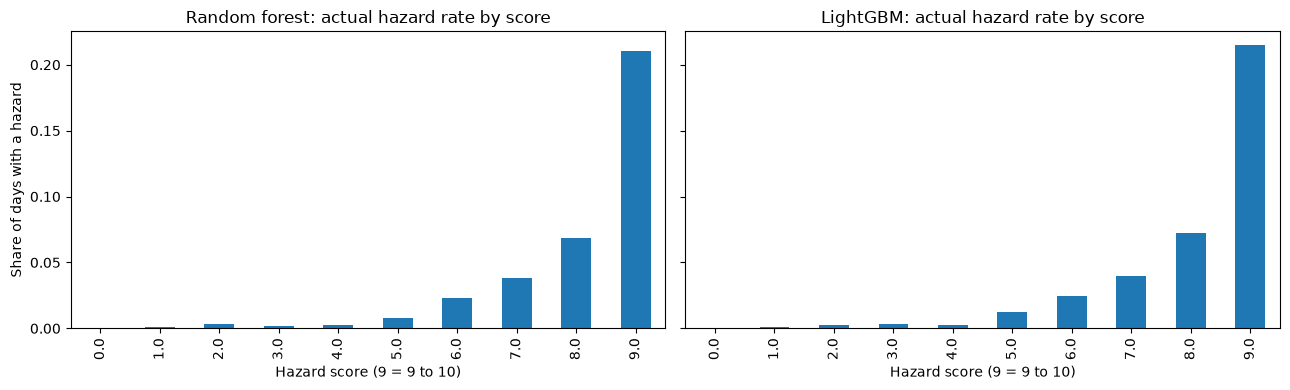

Share of 2023–2024 hazard days that scored 8 or higher: {'Random forest': '83%', 'LightGBM': '81%'}


In [31]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
score_all = {}
for ax, (name, m) in zip(axes, compare.items()):
    cut = np.quantile(m.predict_proba(X_tr)[:, 1], np.linspace(0, 1, 101))
    s = (np.searchsorted(cut, p_test_all[name], side="right").clip(1, 101) - 1) / 10
    score_all[name] = s
    pd.DataFrame({"score": np.floor(s).clip(max=9), "label": y_te.to_numpy()}).groupby("score")["label"].mean() \
        .plot(kind="bar", ax=ax, title=f"{name}: actual hazard rate by score")
    ax.set_xlabel("Hazard score (9 = 9 to 10)"); ax.set_ylabel("Share of days with a hazard")
plt.tight_layout()
plt.savefig(f"{REPORTS}/score_vs_hazard_rate.png", dpi=150, bbox_inches="tight")
plt.show()
print("Share of 2023–2024 hazard days that scored 8 or higher:",
      {n: f"{(s[y_te.to_numpy() == 1] >= 8).mean():.0%}" for n, s in score_all.items()})